# 02 · Extension models: predictors only

**Question this notebook answers:** should the study use the 14 core models, or the 14 plus the extension networks?

It measures only the two **predictors** (alignment and recognition accuracy d′) for the two extension networks, checks whether each is a genuinely different network, and writes `extras.csv`. The H1 power rerun with these real values is in the next notebook, `02b_h1_power.ipynb`.

| Step | What it does | Decides |
|---|---|---|
| 0 | Settings, paths, versions | |
| 1 | Finds the 2,819 stimulus images and the 1,207 CFD recognition photos | Whether the inputs are complete |
| 2 | **Gate.** Re-extracts two released models (FaceNet512, GhostFaceNet) with deepface and compares their alignment to the release | Whether the images and ids are right. If the gate fails, the notebook stops |
| 3 | Detects every face once (RetinaFace) and caches the result | |
| 4 | Extracts w600k_r50 and IRV1-casia | |
| 5 | Alignment and d′ for the new networks, with the code of notebook 01 | |
| 6 | **Copy check.** Representational similarity (RSA) between every pair of models | Which networks are duplicates |
| 7 | Families and `extras.csv` | The final model list |
| 8 | Facts table | |

**Firewall.** This notebook never reads a trait rating, never fits a trait predictor, and never computes leakage, factor structure, disparity or memorability. Inclusion follows the fixed rules in step 7, never the alignment or d′ values.

**Licences.** No face image is displayed or saved. Only embeddings, numbers and plots of numbers leave this notebook.

**Run time (rough, one GPU):** gate 30–90 min (deepface runs RetinaFace inside every call), detection 15–40 min, extraction about 10 min. Every slow step is cached in `results/models/m2/cache/`, so a rerun takes minutes.

## 0. Settings

The paths match the repository layout:

- `IMAGES_DIRS`: the stimulus images named by face id: `datasets/raw/usafd/images_annotations/1.jpg … 2222.jpg` and `datasets/raw/cfd/images_annotations/2223.jpg … 2819.jpg`. The `_landmarks.csv` files next to them are not used.
- `RECOG_DIR`: `datasets/raw/cfd/all`, the 1,207 CFD photos (597 neutral + 610 expressions). The notebook searches it recursively for the photos named in the recognition pairs.
- `WEIGHTS`: the InsightFace ONNX file `models/insightface/buffalo_l/w600k_r50.onnx` inside the repo. The facenet-pytorch weights download themselves on first use into `models/torch/checkpoints/`, and the deepface and RetinaFace weights into `models/deepface/.deepface/weights/`. Every weight file's SHA-256 goes into `environment.json`.

The cell stops immediately if any of these is missing.

In [1]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"   # RetinaFace and deepface need Keras 2 (tf-keras); must be set before TensorFlow loads
import sys, json, glob, hashlib, platform, pickle, subprocess, time
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from scipy.stats import spearmanr
from scipy.spatial.distance import pdist, squareform
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **k):
        return x
try:                       # let TensorFlow (deepface, RetinaFace) share the GPU with PyTorch
    import tensorflow as tf
    for _g in tf.config.list_physical_devices("GPU"):
        tf.config.experimental.set_memory_growth(_g, True)
except Exception:
    pass

REPO = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
ZEN = os.path.join(REPO, "datasets", "external", "hojjati_zenodo")
DATA01 = os.path.join(REPO, "results", "data")                       # outputs of notebook 01
IMAGES_DIRS = [os.path.join(REPO, "datasets", "raw", "usafd", "images_annotations"),   # 1..2222.jpg
               os.path.join(REPO, "datasets", "raw", "cfd", "images_annotations")]     # 2223..2819.jpg
RECOG_DIR = os.path.join(REPO, "datasets", "raw", "cfd", "all")     # 1,207 CFD photos, one folder per identity
MODELS_DIR = os.path.join(REPO, "models")                           # weights live in the repo (keep out of git)
WEIGHTS = {
    "w600k_r50": os.path.join(MODELS_DIR, "insightface", "buffalo_l", "w600k_r50.onnx"),
}
os.environ["TORCH_HOME"] = os.path.join(MODELS_DIR, "torch")         # facenet-pytorch downloads here
os.environ["DEEPFACE_HOME"] = os.path.join(MODELS_DIR, "deepface")   # deepface + RetinaFace: models/deepface/.deepface/weights

OUT = os.path.join(REPO, "results", "models", "m2")
CACHE = os.path.join(OUT, "cache")
FIG_DIR = os.path.join(OUT, "figures")
for d in (OUT, CACHE, FIG_DIR):
    os.makedirs(d, exist_ok=True)

SEED = 1
N_USAFD, N_CFD = 2222, 597
N_TOTAL = N_USAFD + N_CFD
N_BOOT_D = 2000              # identity bootstrap for the d' interval, as in notebook 01

GATE_MODELS = {"Facenet512": "FaceNet512", "GhostFaceNet": "GhostFaceNet"}   # deepface name -> core name
GATE_TOL = 0.005             # |re-extracted - released| alignment, all trials
RUN_GATE_RECOG = True        # also re-extract the gate models on the recognition photos (d' check)

EXTENSIONS = ["w600k_r50", "IRV1-casia"]   # order = order of the duplicate check
DUP_RSA, DUP_COS_MED, DUP_COS_P01 = 0.98, 0.99, 0.95
DUP_SHARED_COS = 0.5   # added 23 Nov 2026 (deviation, see step 6); set to None for the original rule only

# core models: name -> stem of the released embeddings (same as notebook 01)
CORE = {
    "ArcFace18": "ARCFace18_glint360k_embs", "ArcFace34": "ARCFace34_glint360k_embs",
    "ArcFace50": "ARCFace50_glint360k_embs", "ArcFace100": "ARCFace100_glint360k_embs",
    "swinface": "swinface_embs", "FaceNet": "Facenet_embs", "FaceNet512": "Facenet512_embs",
    "Dlib": "Dlib_embs", "VGG-Face": "VGG-Face_embs", "GhostFaceNet": "GhostFaceNet_embs",
    "SFace": "SFace_embs", "DeepFace": "DeepFace_embs", "OpenFace": "OpenFace_embs",
    "DeepID": "DeepID_embs",
}
FAMILY = {"ArcFace18": "ArcFace", "ArcFace34": "ArcFace", "ArcFace50": "ArcFace", "ArcFace100": "ArcFace",
          "swinface": "SwinFace", "FaceNet": "FaceNet", "FaceNet512": "FaceNet", "Dlib": "Dlib",
          "VGG-Face": "VGG-Face", "GhostFaceNet": "GhostFaceNet", "SFace": "SFace",
          "DeepFace": "DeepFace", "OpenFace": "OpenFace", "DeepID": "DeepID"}
# fixed family rule (backbone x training data), set before any value was computed
FAMILY_EXT = {"w600k_r50": "R50-WebFace600K", "IRV1-casia": "IRV1-CASIA"}

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})

def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight")

# ---- environment record ----
env = {"python": sys.version.split()[0], "platform": platform.platform()}
for mod in ("numpy", "pandas", "scipy", "cv2", "torch", "tensorflow", "tf_keras", "onnxruntime", "onnx",
            "deepface", "retinaface", "facenet_pytorch"):
    try:
        m = __import__(mod)
        env[mod] = getattr(m, "__version__", "?")
    except Exception as e:
        env[mod] = f"NOT IMPORTABLE ({type(e).__name__})"
try:
    import torch
    env["cuda"] = bool(torch.cuda.is_available())
    env["gpu"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
except Exception:
    env["cuda"] = False
for k, v in env.items():
    print(f"{k:16s} {v}")
env["weights"] = {os.path.relpath(os.path.join(r, f), REPO): sha256(os.path.join(r, f))
                  for r, _, fs in sorted(os.walk(MODELS_DIR)) for f in sorted(fs)
                  if not f.endswith(".sha256")}
print(f"weight files in {os.path.relpath(MODELS_DIR, REPO)}/: {len(env['weights'])}")
json.dump(env, open(os.path.join(OUT, "environment.json"), "w"), indent=1)

try:
    import tensorflow as tf
    km = tf.keras.layers.Dense.__module__.split(".")[0]          # "tf_keras" (Keras 2) or "keras" (Keras 3)
    print("keras used by TensorFlow (RetinaFace, deepface):", km)
    assert km == "tf_keras", ("TensorFlow is using Keras 3, not tf-keras: install tf-keras, "
                              "restart the kernel and run this cell first")
except ImportError:
    pass

# ---- fail now, not after two hours ----
need = {**{f"weights {k}": v for k, v in WEIGHTS.items()}, "images (USAFD)": IMAGES_DIRS[0],
        "images (CFD)": IMAGES_DIRS[1], "recognition photos": RECOG_DIR}
absent = {k: v for k, v in need.items() if not os.path.exists(v)}
print("\nmissing:", absent if absent else "nothing")
assert not absent, "fix the paths above before running further"

/home/muhammad/Papers/Human alignment of face recognition models in facial social impressions 2/.venv-models/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
I0000 00:00:1795445356.353952  227364 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
W0000 00:00:1795445357.875633  232363 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1795445357.957565  227364 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentio

python           3.11.18
platform         Linux-7.0.0-42-generic-x86_64-with-glibc2.43
numpy            1.26.4
pandas           3.0.6
scipy            1.17.1
cv2              4.11.0
torch            2.2.2+cu121
tensorflow       2.21.0
tf_keras         2.21.0
onnxruntime      1.32.0
onnx             1.23.2
deepface         0.0.105
retinaface       0.0.19
facenet_pytorch  ?
cuda             True
gpu              NVIDIA GeForce RTX 4060 Ti
weight files in models/: 15
keras used by TensorFlow (RetinaFace, deepface): tf_keras

missing: nothing


## 1. Inputs

**Stimulus images.** Row *i* of every embedding array must be face id *i* + 1, exactly as in the release. The cell maps the integer file names in both folders to ids and stops if any id is missing or doubled.

**Recognition photos.** The pair files store paths from the authors' machine. Only the file name is used (`CFD-AF-200-228-N.jpg`), matched anywhere under `RECOG_DIR`.

**Trials and core values** come from the release and from notebook 01's `alignment.csv` and `accuracy.csv`.

In [2]:
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

stim = {}
for p in [q for d in IMAGES_DIRS for q in glob.glob(os.path.join(d, "*"))]:
    stem, ext = os.path.splitext(os.path.basename(p))
    if ext.lower() in IMG_EXT and stem.isdigit():
        k = int(stem)
        assert k not in stim, f"two image files for face id {k}"
        stim[k] = p
missing_ids = sorted(set(range(1, N_TOTAL + 1)) - set(stim))
extra_ids = sorted(set(stim) - set(range(1, N_TOTAL + 1)))
print(f"stimulus images: {len(stim)} found; missing ids: {missing_ids[:10] or 'none'}; "
      f"ids outside 1..{N_TOTAL}: {extra_ids[:10] or 'none'}")
assert not missing_ids, "stimulus images incomplete"
STIM_PATHS = [stim[i] for i in range(1, N_TOTAL + 1)]

# ---- recognition photos ----
pos = np.load(os.path.join(ZEN, "Recognition_task_pairs", "positive_pairs.npy"), allow_pickle=True)
neg = np.load(os.path.join(ZEN, "Recognition_task_pairs", "negative_pairs.npy"), allow_pickle=True)
assert len(pos) == 1494 and len(neg) == 13500
RECOG_KEYS = sorted(set(map(str, np.r_[pos.ravel(), neg.ravel()])))
print(f"recognition pairs: {len(pos)} positive, {len(neg)} negative, {len(RECOG_KEYS)} distinct photos")
assert len(RECOG_KEYS) == 1207

by_name = {}
for root, _, files in os.walk(RECOG_DIR):
    for f in files:
        by_name.setdefault(f, []).append(os.path.join(root, f))
RECOG_PATHS, recog_missing, recog_multi = [], [], 0
for k in RECOG_KEYS:
    hits = by_name.get(os.path.basename(k.replace("\\", "/")), [])
    if not hits:
        recog_missing.append(k)
        RECOG_PATHS.append(None)
        continue
    if len(hits) > 1:
        recog_multi += 1
        assert len({sha256(h) for h in hits}) == 1, f"different files share the name {os.path.basename(k)}"
    RECOG_PATHS.append(hits[0])
print(f"recognition photos found: {len(RECOG_KEYS) - len(recog_missing)}/1207; "
      f"names found in more than one folder (identical bytes): {recog_multi}")
if recog_missing:
    print("MISSING (d' will be BLOCKED):", [os.path.basename(m) for m in recog_missing[:20]])
RECOG_OK = not recog_missing

# ---- trials (identical to notebook 01, section 3) ----
tr_raw = np.load(os.path.join(ZEN, "Split_data", "All_Similarity_trials.npy"))
sc_raw = np.load(os.path.join(ZEN, "Split_data", "All_Similarity_scores.npy"))
invalid = np.all(tr_raw == 0, axis=1)
trials, scores = tr_raw[~invalid], sc_raw[~invalid]
assert len(trials) == 33465
released = pickle.load(open(os.path.join(ZEN, "Models_alignment.pkl"), "rb"))   # stem -> [CFD, USAFD, All]

al01 = pd.read_csv(os.path.join(DATA01, "alignment.csv"))
acc01 = pd.read_csv(os.path.join(DATA01, "accuracy.csv"))
core_tab = (al01[al01.model.isin(list(CORE))][["model", "computed_all", "computed_usafd", "computed_cfd"]]
            .merge(acc01[["model_key", "dprime", "d_lo", "d_hi"]], left_on="model", right_on="model_key")
            .drop(columns="model_key")
            .rename(columns={"computed_all": "align_all", "computed_usafd": "align_usafd",
                             "computed_cfd": "align_cfd"}))
assert len(core_tab) == 14, "notebook 01 outputs incomplete"
core_tab["family"] = core_tab.model.map(FAMILY)
core_tab["source"] = "release"
print(f"\ntrials: {len(trials)}; core models from notebook 01: {len(core_tab)}")

stimulus images: 2819 found; missing ids: none; ids outside 1..2819: none
recognition pairs: 1494 positive, 13500 negative, 1207 distinct photos
recognition photos found: 1207/1207; names found in more than one folder (identical bytes): 0

trials: 33465; core models from notebook 01: 14


**The two measures, copied from notebook 01** (sections 4 and 5, unchanged):

- **Alignment:** L2-normalise, Euclidean distance from the reference to each candidate, model ordering = `argsort + 1`, Spearman ρ with the human ordering per trial, mean over defined trials (all, USAFD-only, CFD-only).
- **d′:** cosine score per pair, d′ = (mean genuine − mean impostor) / √((var genuine + var impostor) / 2), 95% interval from 2,000 resamples of the 566 identities.

In [3]:
def l2norm_rows(x):
    n = np.sqrt(np.sum(np.square(x), axis=1, keepdims=True))
    return x / n

def alignment(embs, trials, scores):
    e = l2norm_rows(embs)
    ed = squareform(pdist(e, "euclidean"))
    d = ed[trials[:, :1], trials[:, 1:]]
    model_order = np.argsort(d, axis=1) + 1
    human = np.argsort(scores[:, 1:], axis=1) + 1
    rs = np.full(len(trials), np.nan)
    for i in range(len(trials)):
        r, _ = spearmanr(human[i], model_order[i])
        rs[i] = r
    ok = ~np.isnan(rs)
    return rs, ok

usafd_t = np.all(trials < N_USAFD, axis=1)
cfd_t = np.all(trials >= N_USAFD, axis=1)

def align3(embs):
    rs, ok = alignment(embs, trials, scores)
    return dict(align_all=float(rs[ok].mean()), align_usafd=float(rs[ok & usafd_t].mean()),
                align_cfd=float(rs[ok & cfd_t].mean()))

def identity_of(path):
    parts = [x for x in str(path).split("/") if x]
    folder = parts[-2] if len(parts) > 1 else "?"
    for x in reversed(parts):
        if x.startswith("CFD-"):
            bits = x.split("-")
            return "-".join(bits[1:3]) if len(bits) >= 3 else folder
    return folder

pos_id = np.array([identity_of(p) for p in pos[:, 0]])
neg_id = np.array([identity_of(p) for p in neg[:, 0]])
uniq_ids = np.unique(np.r_[pos_id, neg_id])
assert len(uniq_ids) == 566
idx_by_id = [np.flatnonzero(np.r_[pos_id, neg_id] == g) for g in uniq_ids]
is_pos = np.r_[np.ones(len(pos)), np.zeros(len(neg))]
key_row = {k: i for i, k in enumerate(RECOG_KEYS)}
pos_rows = np.array([[key_row[str(a)], key_row[str(b)]] for a, b in pos])
neg_rows = np.array([[key_row[str(a)], key_row[str(b)]] for a, b in neg])

def cohen_d(pos_s, neg_s):
    sp = np.sqrt((np.var(pos_s, ddof=1) + np.var(neg_s, ddof=1)) / 2.0)
    return float((pos_s.mean() - neg_s.mean()) / sp) if sp > 0 else np.nan

def dprime_ci(E):
    """E: (1207, d) embeddings in RECOG_KEYS order. Returns d', 95% CI (identity bootstrap)."""
    e = l2norm_rows(np.asarray(E, dtype=np.float64))
    p_s = np.sum(e[pos_rows[:, 0]] * e[pos_rows[:, 1]], axis=1)
    n_s = np.sum(e[neg_rows[:, 0]] * e[neg_rows[:, 1]], axis=1)
    all_s = np.r_[p_s, n_s]
    rng_b = np.random.default_rng(SEED)
    boots = np.full(N_BOOT_D, np.nan)
    for b in range(N_BOOT_D):
        pick = rng_b.integers(0, len(uniq_ids), len(uniq_ids))
        rb = np.concatenate([idx_by_id[q] for q in pick])
        ps, ns = all_s[rb[is_pos[rb] == 1]], all_s[rb[is_pos[rb] == 0]]
        if len(ps) >= 2 and len(ns) >= 2:
            boots[b] = cohen_d(ps, ns)
    v = boots[~np.isnan(boots)]
    return cohen_d(p_s, n_s), float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))

# self-check: the copied code reproduces notebook 01 on two released models
for name in ("FaceNet512", "DeepID"):
    a = align3(np.load(os.path.join(ZEN, "Similarity_task_images_embeds", f"{CORE[name]}.npy")))
    ref = core_tab.set_index("model").loc[name]
    print(f"{name}: alignment all {a['align_all']:.6f} vs notebook 01 {ref.align_all:.6f}")
    assert abs(a["align_all"] - ref.align_all) < 1e-9

FaceNet512: alignment all 0.263487 vs notebook 01 0.263487
DeepID: alignment all 0.151693 vs notebook 01 0.151693


## 2. Gate: can we reproduce the release from these images?

FaceNet512 and GhostFaceNet are re-extracted with deepface, the library and settings the authors used: RetinaFace detection, alignment on, the first face returned. If the images, their ids and the library behave like the authors', the alignment matches the release.

**PASS** = |re-extracted − released| ≤ 0.005 on all trials, for both models. If either fails, the notebook stops here: a failure means the images or ids differ from the authors', and nothing downstream would be comparable.

The same two re-extractions are reused in step 6 to calibrate the copy check (what the similarity of a network with itself looks like after a fresh extraction).

In [4]:
def deepface_embed(model, paths, tag):
    f = os.path.join(CACHE, f"deepface_{model}_{tag}.npy")
    if os.path.exists(f):
        return np.load(f)
    from deepface import DeepFace
    out, n_faces = [], []
    for p in tqdm(paths, desc=f"{model} {tag}"):
        r = DeepFace.represent(img_path=p, model_name=model, detector_backend="retinaface",
                               align=True, enforce_detection=False)
        out.append(np.asarray(r[0]["embedding"], dtype=np.float64))
        n_faces.append(len(r))
    E = np.vstack(out)
    np.save(f, E)
    np.save(f.replace(".npy", "_nfaces.npy"), np.array(n_faces))
    return E

gate_rows, gate_embs = [], {}
for dfname, core_name in GATE_MODELS.items():
    E = deepface_embed(dfname, STIM_PATHS, "stim")
    gate_embs[core_name] = {"stim": E}
    a = align3(E)
    rel_cfd, rel_usafd, rel_all = released[CORE[core_name]]
    row = dict(model=core_name, emb_dim=E.shape[1], **a, released_all=rel_all, released_usafd=rel_usafd,
               diff_all=a["align_all"] - rel_all, diff_usafd=a["align_usafd"] - rel_usafd)
    row["pass"] = abs(row["diff_all"]) <= GATE_TOL
    if RUN_GATE_RECOG and RECOG_OK:
        R = deepface_embed(dfname, RECOG_PATHS, "recog")
        gate_embs[core_name]["recog"] = R
        d, lo, hi = dprime_ci(R)
        row.update(dprime=d, released_dprime=float(core_tab.set_index("model").loc[core_name, "dprime"]))
        row["diff_dprime"] = d - row["released_dprime"]
    gate_rows.append(row)
gate = pd.DataFrame(gate_rows)
gate.to_csv(os.path.join(OUT, "gate.csv"), index=False)
print(gate.round(5).to_string(index=False))
GATE_PASS = bool(gate["pass"].all())
print(f"\nGATE {'PASS' if GATE_PASS else 'FAIL'} (tolerance {GATE_TOL} on all-trial alignment)")
if "diff_dprime" in gate:
    print("d' differences are reported, not judged: the recognition photos are full-size CFD files "
          "and small detector differences move d' more than alignment.")
if not GATE_PASS:
    raise RuntimeError("Gate failed: check IMAGES_DIRS, the id order of the files, and the deepface version. "
                       "Stop here and report gate.csv.")

       model  emb_dim  align_all  align_usafd  align_cfd  released_all  released_usafd  diff_all  diff_usafd  pass  dprime  released_dprime  diff_dprime
  FaceNet512      512    0.26368      0.24877    0.28535       0.26349         0.24788    0.0002      0.0009  True 4.19071          4.19071          0.0
GhostFaceNet      512    0.20665      0.19016    0.22909       0.20665         0.19016    0.0000      0.0000  True 3.39403          3.39403          0.0

GATE PASS (tolerance 0.005 on all-trial alignment)
d' differences are reported, not judged: the recognition photos are full-size CFD files and small detector differences move d' more than alignment.


## 3. Face detection (once per image)

RetinaFace runs once on each of the 4,026 images and the result is cached. Every extension network then uses the same detection, cropped the way that network expects (step 4).

- The highest-scoring face is kept.
- If nothing is found at the default threshold (0.9), the cell retries at 0.5.
- If still nothing is found, the whole image is used: a centred square, with the five landmarks placed where the ArcFace template expects them. Every such case is counted and reported.

Two details are checked rather than assumed: the box format (corners vs. corner + size) and which eye is which. The eyes and mouth corners are ordered by their x position in the image, so the landmark names do not matter.

In [5]:
def _detect_one(path):
    from retinaface import RetinaFace
    for thr in (0.9, 0.5):
        try:
            r = RetinaFace.detect_faces(path, threshold=thr)
        except TypeError:                      # older signature without threshold
            r = RetinaFace.detect_faces(path)
        if isinstance(r, dict) and len(r):
            best = max(r.values(), key=lambda f: float(f["score"]))
            return dict(status="ok" if thr == 0.9 else "low_threshold", n=len(r), score=float(best["score"]),
                        box=[float(v) for v in best["facial_area"]],
                        lm={k: [float(c) for c in v] for k, v in best["landmarks"].items()})
    return dict(status="none", n=0, score=None, box=None, lm=None)

def detect_all(paths, tag):
    f = os.path.join(CACHE, f"retinaface_{tag}.json")
    det = json.load(open(f)) if os.path.exists(f) else {}
    todo = [p for p in paths if p not in det]
    for i, p in enumerate(tqdm(todo, desc=f"detect {tag}")):
        det[p] = _detect_one(p)
        if (i + 1) % 200 == 0:
            json.dump(det, open(f, "w"))
    json.dump(det, open(f, "w"))
    return [det[p] for p in paths]

DET_STIM = detect_all(STIM_PATHS, "stim")
DET_RECOG = detect_all([p for p in RECOG_PATHS if p], "recog") if RECOG_OK else []

def det_summary(dets, tag):
    s = pd.Series([d["status"] for d in dets]).value_counts()
    multi = sum(d["n"] > 1 for d in dets)
    print(f"{tag}: { {k: int(v) for k, v in s.items()} }; images with more than one face: {multi}")
    return s

det_counts = {"stim": det_summary(DET_STIM, "stimuli"),
              "recog": det_summary(DET_RECOG, "recognition") if DET_RECOG else pd.Series(dtype=int)}

detect stim: 0it [00:00, ?it/s]
detect recog: 0it [00:00, ?it/s]

stimuli: {'ok': 2758, 'low_threshold': 36, 'none': 25}; images with more than one face: 0
recognition: {'ok': 1203, 'low_threshold': 4}; images with more than one face: 0


In [6]:
ARCFACE_DST = np.array([[38.2946, 51.6963], [73.5318, 51.5014], [56.0252, 71.7366],
                        [41.5493, 92.3655], [70.7299, 92.2041]])   # InsightFace arcface_dst, 112 x 112

def as_xyxy(box, lm):
    """Return the box as x1, y1, x2, y2: the reading in which both eyes fall inside it."""
    x1, y1, a, b = box
    eyes = np.array([lm["right_eye"], lm["left_eye"]]) if lm else None
    for c in ((x1, y1, a, b), (x1, y1, x1 + a, y1 + b)):
        if c[2] > c[0] and c[3] > c[1] and eyes is not None and np.all(
                (eyes[:, 0] > c[0]) & (eyes[:, 0] < c[2]) & (eyes[:, 1] > c[1]) & (eyes[:, 1] < c[3])):
            return c, c == (x1, y1, a, b)
    return (x1, y1, a, b), True

def five_points(lm):
    """Landmarks in template order: eye left-in-image, eye right-in-image, nose, mouth left, mouth right."""
    eyes = sorted([lm["right_eye"], lm["left_eye"]], key=lambda p: p[0])
    mouth = sorted([lm["mouth_right"], lm["mouth_left"]], key=lambda p: p[0])
    return np.array(eyes + [lm["nose"]] + mouth, dtype=np.float64)

def geometry(det, shape):
    """Box (x1,y1,x2,y2) and 5 landmarks for one image; whole-image fallback when nothing was found."""
    h, w = shape[:2]
    if det["status"] == "none":
        s = min(h, w)
        x0, y0 = (w - s) / 2, (h - s) / 2
        return (x0, y0, x0 + s, y0 + s), ARCFACE_DST / 112.0 * s + [x0, y0]
    box, _ = as_xyxy(det["box"], det["lm"])
    return box, five_points(det["lm"])

n_xyxy = sum(as_xyxy(d["box"], d["lm"])[1] for d in DET_STIM + DET_RECOG if d["status"] != "none")
n_det = sum(d["status"] != "none" for d in DET_STIM + DET_RECOG)
print(f"box format: corners (x1,y1,x2,y2) in {n_xyxy}/{n_det} detections")
# landmark sanity: eyes above nose above mouth in image coordinates
bad = 0
for d in DET_STIM + DET_RECOG:
    if d["status"] != "none":
        p = five_points(d["lm"])
        bad += not (max(p[0, 1], p[1, 1]) < p[2, 1] < min(p[3, 1], p[4, 1]))
print(f"detections with eyes / nose / mouth out of vertical order: {bad}")

box format: corners (x1,y1,x2,y2) in 4001/4001 detections
detections with eyes / nose / mouth out of vertical order: 2


## 4. Extract the extension networks

| Network | Weights | Trained on | Input | Normalisation |
|---|---|---|---|---|
| w600k_r50 | InsightFace `buffalo_l` (ResNet-50) | WebFace600K (Zhu et al., 2021) | 112 × 112, aligned to the ArcFace template with the 5 landmarks | read from the model file, as InsightFace does |
| IRV1-casia | facenet-pytorch `InceptionResnetV1("casia-webface")` | CASIA-WebFace (Yi et al., 2014) | 160 × 160 square crop of the box, margin 0 | (x − 127.5) / 128 (`fixed_image_standardization`) |

**Normalisation of the ONNX file.** InsightFace looks at the first nodes of each model: if the file already subtracts and scales (nodes named `Sub`/`_minus` and `Mul`/`_mul`), it feeds raw pixels (mean 0, std 1); otherwise (x − 127.5) / 127.5. The cell applies the same rule and prints which one each file uses. Pixels are RGB.

**cuDNN off for PyTorch.** In this venv PyTorch 2.2.2 cannot load cuDNN, so the IRV1 networks run on plain CUDA kernels (`torch.backends.cudnn.enabled = False`). Same arithmetic, different kernels: embeddings differ from a cuDNN run only at float rounding level.

**IRV1 crop.** facenet-pytorch's own detector (MTCNN) makes its boxes square and crops with margin 0 by default. The RetinaFace box is squared the same way, clipped to the image, and resized to 160 × 160.

**Licences.** InsightFace pretrained models: non-commercial research use only. facenet-pytorch: MIT licence; its weights are ported from David Sandberg's `facenet` (MIT).

In [7]:
import onnxruntime as ort
import onnx

def umeyama(src, dst):
    """Least-squares similarity transform src -> dst (same as skimage SimilarityTransform)."""
    n = src.shape[0]
    mu_s, mu_d = src.mean(0), dst.mean(0)
    sc, dc = src - mu_s, dst - mu_d
    U, S, Vt = np.linalg.svd(dc.T @ sc / n)
    D = np.eye(2)
    if np.linalg.det(U) * np.linalg.det(Vt) < 0:
        D[1, 1] = -1
    R = U @ D @ Vt
    scale = np.trace(np.diag(S) @ D) / ((sc ** 2).sum() / n)
    M = np.zeros((2, 3))
    M[:, :2] = scale * R
    M[:, 2] = mu_d - scale * R @ mu_s
    return M

assert np.allclose(umeyama(ARCFACE_DST, ARCFACE_DST), [[1, 0, 0], [0, 1, 0]], atol=1e-9)

def crop112(img_bgr, lm5):
    return cv2.warpAffine(img_bgr, umeyama(lm5, ARCFACE_DST), (112, 112), borderValue=0.0)

def crop160(img_bgr, box):
    h, w = img_bgr.shape[:2]
    x1, y1, x2, y2 = box
    s = max(x2 - x1, y2 - y1)
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    x1, y1, x2, y2 = (int(round(max(cx - s / 2, 0))), int(round(max(cy - s / 2, 0))),
                      int(round(min(cx + s / 2, w))), int(round(min(cy + s / 2, h))))
    return cv2.resize(img_bgr[y1:y2, x1:x2], (160, 160), interpolation=cv2.INTER_AREA)

def onnx_input_norm(path):
    g = onnx.load(path).graph
    sub = any(n.name.startswith("Sub") or n.name.startswith("_minus") for n in g.node[:8])
    mul = any(n.name.startswith("Mul") or n.name.startswith("_mul") for n in g.node[:8])
    return (0.0, 1.0) if (sub and mul) else (127.5, 127.5)

providers = [p for p in ("CUDAExecutionProvider", "CPUExecutionProvider") if p in ort.get_available_providers()]
ONNX = {}
for name, path in WEIGHTS.items():
    assert os.path.exists(path), f"missing weights for {name}: {path}"
    sess = ort.InferenceSession(path, providers=providers)
    inp = sess.get_inputs()[0]
    mean, std = onnx_input_norm(path)
    ONNX[name] = dict(sess=sess, inp=inp.name, dynamic=not isinstance(inp.shape[0], int),
                      mean=mean, std=std, sha256=sha256(path), path=path)
    print(f"{name}: input {inp.shape}, normalisation (x - {mean}) / {std}, "
          f"providers {sess.get_providers()}, sha256 {ONNX[name]['sha256'][:16]}…")

import torch
from facenet_pytorch import InceptionResnetV1
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TORCH_CUDNN = False   # torch 2.2.2 cannot load cuDNN in this venv ("cuDNN could not be found"); plain CUDA kernels instead
if hasattr(torch, "backends"):
    torch.backends.cudnn.enabled = TORCH_CUDNN
IRV1 = {"IRV1-casia": "casia-webface"}
IRV1_NET = {n: InceptionResnetV1(pretrained=w).eval().to(DEVICE) for n, w in IRV1.items()}

def irv1_weight_file(tag):
    for d in {os.path.join(os.environ["TORCH_HOME"], "checkpoints"),
              os.path.join(torch.hub.get_dir(), "checkpoints")}:
        hits = glob.glob(os.path.join(d, f"*{tag}*.pt"))
        if hits:
            return hits[0]
    return None

for n, w in IRV1.items():
    f = irv1_weight_file(w)
    print(f"{n}: device {DEVICE}, cuDNN {'on' if TORCH_CUDNN else 'off'}, weights {os.path.basename(f) if f else 'NOT FOUND'}, "
          f"sha256 {sha256(f)[:16] + '…' if f else '-'}")

w600k_r50: input ['None', 3, 112, 112], normalisation (x - 127.5) / 127.5, providers ['CPUExecutionProvider'], sha256 4c06341c33c2ca1f…
IRV1-casia: device cuda, cuDNN off, weights 20180408-102900-casia-webface.pt, sha256 7a67afdbbc995fce…


In [8]:
def run_onnx(name, crops_rgb):
    m = ONNX[name]
    x = ((crops_rgb.astype(np.float32) - m["mean"]) / m["std"]).transpose(0, 3, 1, 2)
    if m["dynamic"]:
        return m["sess"].run(None, {m["inp"]: x})[0]
    return np.vstack([m["sess"].run(None, {m["inp"]: x[i:i + 1]})[0] for i in range(len(x))])

def run_irv1(name, crops_rgb):
    x = (crops_rgb.astype(np.float32) - 127.5) / 128.0
    with torch.no_grad():
        t = torch.from_numpy(np.ascontiguousarray(x.transpose(0, 3, 1, 2))).to(DEVICE)
        return IRV1_NET[name](t).cpu().numpy()

def extract(paths, dets, tag, batch=64):
    files = {n: os.path.join(CACHE, f"{n}_{tag}.npy") for n in EXTENSIONS}
    if all(os.path.exists(f) for f in files.values()):
        return {n: np.load(f) for n, f in files.items()}
    out = {n: [] for n in EXTENSIONS}
    for s in tqdm(range(0, len(paths), batch), desc=f"extract {tag}"):
        c112, c160 = [], []
        for p, d in zip(paths[s:s + batch], dets[s:s + batch]):
            img = cv2.imread(p, cv2.IMREAD_COLOR)
            assert img is not None, f"cannot read {p}"
            box, lm5 = geometry(d, img.shape)
            c112.append(cv2.cvtColor(crop112(img, lm5), cv2.COLOR_BGR2RGB))
            c160.append(cv2.cvtColor(crop160(img, box), cv2.COLOR_BGR2RGB))
        c112, c160 = np.stack(c112), np.stack(c160)
        for n in ONNX:
            out[n].append(run_onnx(n, c112))
        for n in IRV1_NET:
            out[n].append(run_irv1(n, c160))
    res = {n: np.vstack(v).astype(np.float64) for n, v in out.items()}
    for n, f in files.items():
        np.save(f, res[n])
    return res

EXT_STIM = extract(STIM_PATHS, DET_STIM, "stim")
EXT_RECOG = extract(RECOG_PATHS, DET_RECOG, "recog") if RECOG_OK else {}
for n in EXTENSIONS:
    E = EXT_STIM[n]
    print(f"{n:14s} stim {E.shape}, finite {np.isfinite(E).all()}, "
          f"recog {EXT_RECOG[n].shape if n in EXT_RECOG else 'BLOCKED'}")

w600k_r50      stim (2819, 512), finite True, recog (1207, 512)
IRV1-casia     stim (2819, 512), finite True, recog (1207, 512)


## 5. Predictors: alignment and d′

Same code as notebook 01, applied to the two new networks. The two gate re-extractions are listed too, so you can see how far a fresh extraction of a known network moves the numbers.

In [9]:
rows = []
for n in EXTENSIONS:
    r = dict(model=n, family=FAMILY_EXT[n], source="own extraction", emb_dim=EXT_STIM[n].shape[1],
             **align3(EXT_STIM[n]))
    if n in EXT_RECOG:
        r["dprime"], r["d_lo"], r["d_hi"] = dprime_ci(EXT_RECOG[n])
    rows.append(r)
for n, e in gate_embs.items():
    r = dict(model=f"{n} (re-extracted)", family=FAMILY[n], source="gate re-extraction",
             emb_dim=e["stim"].shape[1], **align3(e["stim"]))
    if "recog" in e:
        r["dprime"], r["d_lo"], r["d_hi"] = dprime_ci(e["recog"])
    rows.append(r)
ext_tab = pd.DataFrame(rows)
for c in ("dprime", "d_lo", "d_hi"):
    if c not in ext_tab:
        ext_tab[c] = np.nan                 # d' BLOCKED (recognition photos incomplete)
core_tab["emb_dim"] = [np.load(os.path.join(ZEN, "Similarity_task_images_embeds", f"{CORE[m]}.npy")).shape[1]
                       for m in core_tab.model]
pred = pd.concat([core_tab, ext_tab], ignore_index=True)
cols = ["model", "family", "source", "emb_dim", "align_usafd", "align_all", "align_cfd", "dprime", "d_lo", "d_hi"]
pred = pred[cols]
pred.to_csv(os.path.join(OUT, "predictors_m2.csv"), index=False)
print(pred.round(4).to_string(index=False))

                      model          family             source  emb_dim  align_usafd  align_all  align_cfd  dprime    d_lo    d_hi
                  ArcFace18         ArcFace            release      512       0.1782     0.1987     0.2327  6.2954  6.0576  6.5460
                  ArcFace34         ArcFace            release      512       0.1573     0.1721     0.1958  8.0514  7.7756  8.3425
                  ArcFace50         ArcFace            release      512       0.1419     0.1592     0.1878  8.6209  8.3756  8.8836
                 ArcFace100         ArcFace            release      512       0.1299     0.1447     0.1712  9.5741  9.2984  9.8518
                   swinface        SwinFace            release      512       0.1390     0.1523     0.1759  7.2028  6.8758  7.5486
                    FaceNet         FaceNet            release      128       0.2478     0.2637     0.2883  4.6207  4.4597  4.7947
                 FaceNet512         FaceNet            release      512       0.247

**Figure M1.** Alignment (USAFD-only trials, the H1 predictor) against d′. Grey: core models. Coloured: the new networks. This is a picture of the predictors only; it plays no part in the inclusion decision.

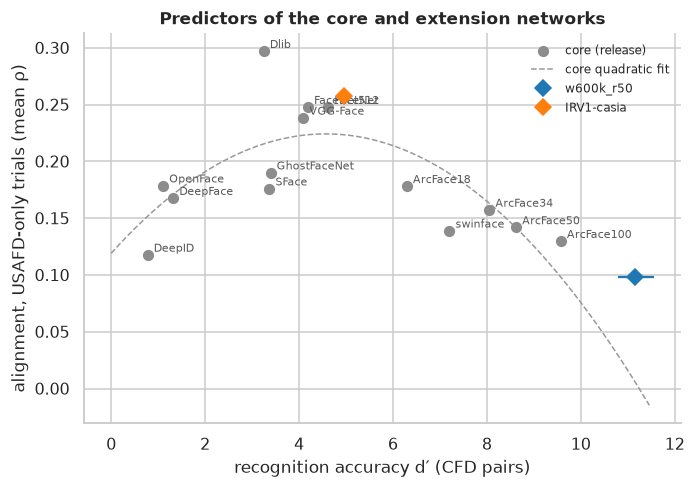

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.6))
c = pred[pred.source == "release"]
ax.scatter(c.dprime, c.align_usafd, s=40, color="0.55", zorder=3, label="core (release)")
for _, r in c.iterrows():
    ax.annotate(r.model, (r.dprime, r.align_usafd), fontsize=7, color="0.35",
                xytext=(4, 2), textcoords="offset points")
x = pred[pred.source == "own extraction"].dropna(subset=["dprime"])
pal = dict(zip(EXTENSIONS, sns.color_palette("tab10", 4)))
for _, r in x.iterrows():
    ax.errorbar(r.dprime, r.align_usafd, xerr=[[r.dprime - r.d_lo], [r.d_hi - r.dprime]], fmt="D",
                ms=7, color=pal[r.model], zorder=4, label=r.model)
dd = np.linspace(0, max(pred.dprime.max(), 10) + 0.3, 200)
cf = np.polyfit(c.dprime, c.align_usafd, 2)
ax.plot(dd, np.polyval(cf, dd), ls="--", lw=1, color="0.6", label="core quadratic fit")
ax.set_xlabel("recognition accuracy d′ (CFD pairs)")
ax.set_ylabel("alignment, USAFD-only trials (mean ρ)")
ax.set_title("Predictors of the core and extension networks")
ax.legend(fontsize=8, frameon=False, loc="best")
save(fig, "M1_alignment_vs_dprime")
plt.show()

## 6. Copy check: is each new network really a different network?

A network that is a re-release of a core model would add a row to the regression without adding information, and would make the test look stronger than it is.

- **RSA.** For each model, the 2,819 × 2,819 matrix of Euclidean distances between its L2-normalised embeddings. For each pair of models, the Pearson correlation of the two upper triangles (about 4 million face pairs). It works across embedding sizes.
- **Row-wise cosine.** For pairs with the same embedding size: the cosine between the two models' embeddings of the same face, summarised by its median and 1st percentile. It is high only if the two networks share weights (same output space).
- **Calibration.** The gate re-extractions against their released versions show the values a network reaches against itself after a fresh extraction.

**Duplicate rule (fixed in advance):** RSA ≥ 0.98, or median cosine ≥ 0.99 and 1st percentile ≥ 0.95, against any model already in the set (the 14 core models, then the extensions in the order w600k_r50, IRV1-casia).

**Deviation (23 Nov 2026), shared-weights test.** The first run showed that this rule cannot flag a copy: a released network against its own fresh extraction reached only RSA 0.967 / 0.839 and a 1st-percentile cosine of 0.80 / 0.19 (FaceNet512 / GhostFaceNet). Row-wise cosine separates the cases instead: a median above 0.99 for the same weights, and about 0 (−0.01 to 0.03) for every pair of networks with different weights. A network is therefore also a duplicate if its **median row-wise cosine ≥ 0.5** with a model already in the set. The cut sits in the middle of that gap; it was set from the copy-check statistics only, never from alignment or d′. `DUP_SHARED_COS = None` restores the original rule.

In [11]:
rsa_models = {m: np.load(os.path.join(ZEN, "Similarity_task_images_embeds", f"{CORE[m]}.npy")) for m in CORE}
rsa_models.update({n: EXT_STIM[n] for n in EXTENSIONS})
rsa_models.update({f"{n} (re-extracted)": e["stim"] for n, e in gate_embs.items()})
names = list(rsa_models)

Z = np.empty((len(names), N_TOTAL * (N_TOTAL - 1) // 2), dtype=np.float32)
for i, n in enumerate(names):
    v = pdist(l2norm_rows(np.asarray(rsa_models[n], dtype=np.float64)), "euclidean")
    Z[i] = ((v - v.mean()) / v.std()).astype(np.float32)
G = np.zeros((len(names), len(names)))
for s in range(0, Z.shape[1], 500_000):                  # float64 accumulation, in chunks
    zc = Z[:, s:s + 500_000].astype(np.float64)
    G += zc @ zc.T
RSA = pd.DataFrame(G / Z.shape[1], index=names, columns=names)
del Z
RSA.to_csv(os.path.join(OUT, "rsa_matrix.csv"))

def rowcos(a, b):
    c = np.sum(l2norm_rows(a) * l2norm_rows(b), axis=1)
    return float(np.median(c)), float(np.percentile(c, 1))

cos_rows = []
for i, a in enumerate(names):
    for b in names[i + 1:]:
        if rsa_models[a].shape[1] == rsa_models[b].shape[1] and (a in EXTENSIONS or b in EXTENSIONS):
            med, p01 = rowcos(rsa_models[a], rsa_models[b])
            cos_rows.append(dict(a=a, b=b, dim=rsa_models[a].shape[1], rsa=RSA.loc[a, b],
                                 cos_median=med, cos_p01=p01))
cos_tab = pd.DataFrame(cos_rows)
cos_tab.to_csv(os.path.join(OUT, "rowwise_cosine.csv"), index=False)

iu = np.triu_indices(len(names), 1)
pairs = pd.DataFrame({"a": np.array(names)[iu[0]], "b": np.array(names)[iu[1]], "rsa": RSA.values[iu]})
print("10 highest RSA pairs:")
print(pairs.sort_values("rsa", ascending=False).head(10).round(4).to_string(index=False))
print("\nrow-wise cosine (same embedding size, at least one extension network):")
print(cos_tab.sort_values("cos_median", ascending=False).round(4).to_string(index=False)
      if len(cos_tab) else "  no extension network shares an embedding size with another model")

print("\ncalibration (same network, fresh extraction vs release):")
for n in gate_embs:
    a = f"{n} (re-extracted)"
    med, p01 = rowcos(rsa_models[a], rsa_models[n])
    print(f"  {n}: RSA {RSA.loc[a, n]:.4f}, row-wise cosine median {med:.4f}, p01 {p01:.4f}")
calib_min = min(RSA.loc[f"{n} (re-extracted)", n] for n in gate_embs)
print(f"  -> lowest same-network RSA: {calib_min:.4f}; duplicate threshold {DUP_RSA} is "
      f"{'below it (the rule can detect copies)' if calib_min >= DUP_RSA else 'ABOVE it: a copy could slip under the rule; report this'}")

10 highest RSA pairs:
           a                           b    rsa
  FaceNet512   FaceNet512 (re-extracted) 0.9670
GhostFaceNet GhostFaceNet (re-extracted) 0.8388
     FaceNet                  FaceNet512 0.7390
   ArcFace50                  ArcFace100 0.7352
     FaceNet   FaceNet512 (re-extracted) 0.7322
   ArcFace34                   ArcFace50 0.6817
  ArcFace100                   w600k_r50 0.6618
  IRV1-casia   FaceNet512 (re-extracted) 0.6485
  FaceNet512                  IRV1-casia 0.6431
     FaceNet                  IRV1-casia 0.6373

row-wise cosine (same embedding size, at least one extension network):
           a                           b  dim    rsa  cos_median  cos_p01
  IRV1-casia   FaceNet512 (re-extracted)  512 0.6485      0.0239  -0.0832
  FaceNet512                  IRV1-casia  512 0.6431      0.0235  -0.0860
  IRV1-casia GhostFaceNet (re-extracted)  512 0.3423      0.0095  -0.0998
GhostFaceNet                  IRV1-casia  512 0.3394      0.0094  -0.0991
GhostFac

In [12]:
in_set = list(CORE)
dup_rows = []
for n in EXTENSIONS:
    hits = []
    for m in in_set:
        r = RSA.loc[n, m]
        reason = None
        if r >= DUP_RSA:
            reason = f"RSA {r:.4f} >= {DUP_RSA}"
        elif rsa_models[n].shape[1] == rsa_models[m].shape[1]:
            med, p01 = rowcos(rsa_models[n], rsa_models[m])
            if med >= DUP_COS_MED and p01 >= DUP_COS_P01:
                reason = f"cosine median {med:.4f}, p01 {p01:.4f}"
            elif DUP_SHARED_COS is not None and med >= DUP_SHARED_COS:
                reason = f"shared weights: cosine median {med:.4f} >= {DUP_SHARED_COS}"
        if reason:
            hits.append(f"{m} ({reason})")
    nearest = RSA.loc[n, in_set].idxmax()
    dup_rows.append(dict(model=n, duplicate=bool(hits), duplicate_of="; ".join(hits) or "-",
                         nearest=nearest, nearest_rsa=RSA.loc[n, nearest]))
    if not hits:
        in_set.append(n)
dups = pd.DataFrame(dup_rows)
print(dups.round(4).to_string(index=False))

     model  duplicate duplicate_of    nearest  nearest_rsa
 w600k_r50      False            - ArcFace100       0.6618
IRV1-casia      False            - FaceNet512       0.6431


**Figure M2.** RSA between all models. Bright cells = models that see faces the same way.

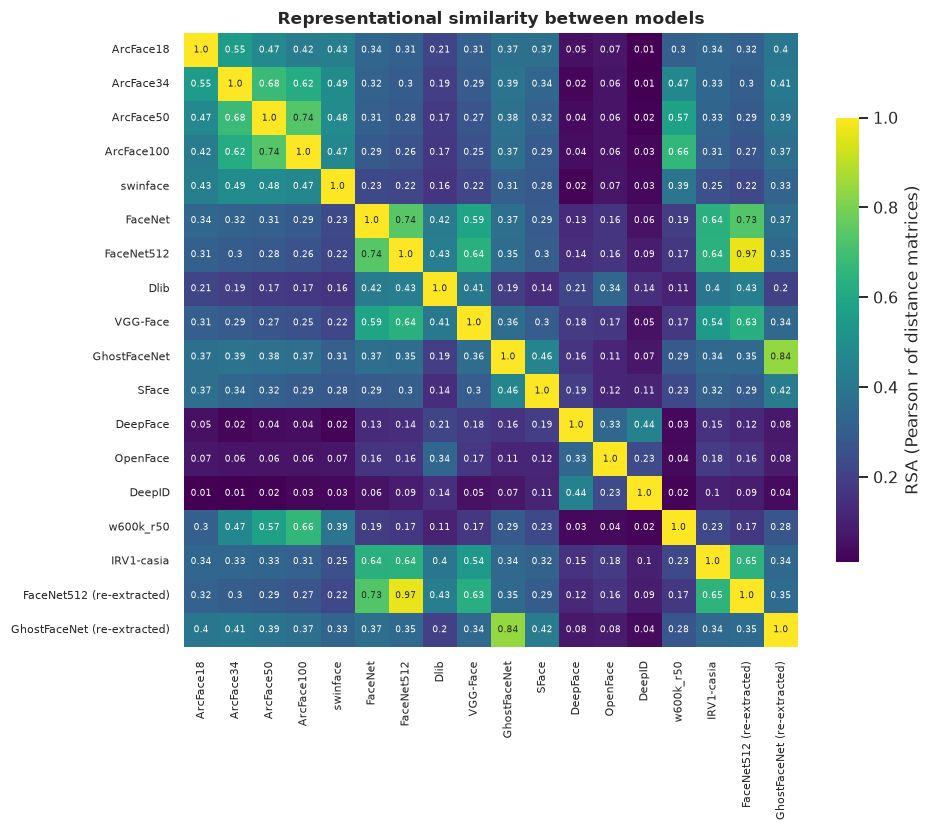

In [13]:
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(RSA, cmap="viridis", vmin=max(0, RSA.values.min()), vmax=1, square=True,
            cbar_kws={"label": "RSA (Pearson r of distance matrices)", "shrink": 0.7},
            annot=RSA.round(2), fmt="", annot_kws={"fontsize": 6}, ax=ax)
ax.set_title("Representational similarity between models")
ax.tick_params(labelsize=7)
save(fig, "M2_rsa_matrix")
plt.show()

## 7. Inclusion, families and `extras.csv`

A network enters `extras.csv` if it is **not a duplicate** (step 6, including the shared-weights test) and its **d′ exists** (all 1,207 recognition photos found). Nothing else is used.

Family = backbone × training data: w600k_r50 and IRV1-casia each form a new family. `extras.csv` carries the USAFD-only alignment, the H1 predictor.

In [14]:
inc = ext_tab[ext_tab.source == "own extraction"].merge(dups, on="model")
inc["included"] = ~inc.duplicate & inc.dprime.notna()
inc["reason"] = np.where(inc.duplicate, "duplicate of " + inc.duplicate_of,
                         np.where(inc.dprime.isna(), "d' BLOCKED", "included"))
extras = inc[inc.included][["model", "family", "align_usafd", "dprime"]].rename(columns={"align_usafd": "align"})
EXTRAS_CSV = os.path.join(OUT, "extras.csv")
extras.to_csv(EXTRAS_CSV, index=False)
fams = pd.concat([core_tab[["model", "family"]], extras[["model", "family"]]])
print(inc[["model", "family", "reason"]].to_string(index=False))
print(f"\nfinal set: {14 + len(extras)} models in {fams.family.nunique()} families "
      f"(core: 14 in {core_tab.family.nunique()})")
print(f"wrote {os.path.relpath(EXTRAS_CSV, REPO)}  -> next: 02b_h1_power.ipynb")
print(extras.round(5).to_string(index=False))

     model          family   reason
 w600k_r50 R50-WebFace600K included
IRV1-casia      IRV1-CASIA included

final set: 16 models in 12 families (core: 14 in 10)
wrote results/models/m2/extras.csv  -> next: 02b_h1_power.ipynb
     model          family   align   dprime
 w600k_r50 R50-WebFace600K 0.09835 11.15846
IRV1-casia      IRV1-CASIA 0.25720  4.95750


## 8. Facts table

Every number the report or the OSF page needs, in one place (`facts_02.json`).

In [15]:
facts = {
    "stimulus_images": len(STIM_PATHS), "recognition_photos_found": len(RECOG_KEYS) - len(recog_missing),
    "gate_pass": GATE_PASS,
    "gate": {r.model: {"diff_all": round(r.diff_all, 6), "diff_usafd": round(r.diff_usafd, 6),
                       "diff_dprime": (round(r.diff_dprime, 4) if "diff_dprime" in gate and pd.notna(r.diff_dprime)
                                       else None)} for r in gate.itertuples()},
    "detection_stim": {k: int(v) for k, v in det_counts["stim"].items()},
    "detection_recog": {k: int(v) for k, v in det_counts["recog"].items()},
    "onnx": {n: {"sha256": m["sha256"], "input_mean": m["mean"], "input_std": m["std"]} for n, m in ONNX.items()},
    "torch_cudnn": TORCH_CUDNN,
    "irv1_weights": {n: (sha256(f) if (f := irv1_weight_file(w)) else None) for n, w in IRV1.items()},
    "predictors": {r.model: {"align_usafd": round(r.align_usafd, 6), "align_all": round(r.align_all, 6),
                             "dprime": (round(r.dprime, 4) if pd.notna(r.dprime) else None)}
                   for r in ext_tab.itertuples()},
    "calibration_min_same_network_rsa": round(float(calib_min), 4),
    "duplicate_rule": (f"RSA >= {DUP_RSA}, or cosine median >= {DUP_COS_MED} and p01 >= {DUP_COS_P01}"
                       + (f", or cosine median >= {DUP_SHARED_COS} (shared weights; deviation 23 Nov 2026)"
                          if DUP_SHARED_COS is not None else "")),
    "duplicates": {r.model: r.duplicate_of for r in dups.itertuples()},
    "nearest_rsa": {r.model: [r.nearest, round(float(r.nearest_rsa), 4)] for r in dups.itertuples()},
    "included": extras.model.tolist(),
    "final_M": 14 + len(extras), "final_families": int(fams.family.nunique()),
}
json.dump(facts, open(os.path.join(OUT, "facts_02.json"), "w"), indent=1, default=str)
for k, v in facts.items():
    print(f"{k:34s} {v}")

stimulus_images                    2819
recognition_photos_found           1207
gate_pass                          True
gate                               {'FaceNet512': {'diff_all': 0.000197, 'diff_usafd': 0.000897, 'diff_dprime': 0.0}, 'GhostFaceNet': {'diff_all': 0.0, 'diff_usafd': 0.0, 'diff_dprime': 0.0}}
detection_stim                     {'ok': 2758, 'low_threshold': 36, 'none': 25}
detection_recog                    {'ok': 1203, 'low_threshold': 4}
onnx                               {'w600k_r50': {'sha256': '4c06341c33c2ca1f86781dab0e829f88ad5b64be9fba56e56bc9ebdefc619e43', 'input_mean': 127.5, 'input_std': 127.5}}
torch_cudnn                        False
irv1_weights                       {'IRV1-casia': '7a67afdbbc995fce5e10128675e318799a70698c2f433ba75dd7eb9a2f096e7d'}
predictors                         {'w600k_r50': {'align_usafd': 0.098347, 'align_all': 0.115111, 'dprime': 11.1585}, 'IRV1-casia': {'align_usafd': 0.257204, 'align_all': 0.268818, 'dprime': 4.9575}, 'FaceNet51